# Exercise7.02: Northern Hemisphere surface temperature analysis

LU MENGJIE — MC643920  
Suggested Exercise 07 · Practice 01

Data: `northern_surface_temperature.csv`. Historical publisher data; anomalies in °C relative to 1951–1980.

## Exercise7.02 — 01. Read and transpose monthly anomalies

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

DATA_DIR = Path('../../Datasets')
pd.set_option('display.max_columns', 8)
pd.set_option('display.width', 110)
print('LU MENGJIE | MC643920 | Python 3 / Seaborn', sns.__version__)
sns.set_theme()
raw = pd.read_csv(DATA_DIR / 'northern_surface_temperature.csv', index_col='Year')
data = raw.transpose()
print('Raw shape:', raw.shape, '| Transposed shape:', data.shape)
print('Source years:', raw.index.min(), 'to', raw.index.max())
display(data.iloc[:4, :6])

LU MENGJIE | MC643920 | Python 3 / Seaborn 0.13.2
Raw shape: (139, 12) | Transposed shape: (12, 139)
Source years: 1880 to 2018


Year,1880,1881,1882,1883,1884,1885
Jan,-0.34,-0.30,0.28,-0.56,-0.16,-0.99
Feb,-0.50,-0.21,0.23,-0.64,-0.11,-0.43
Mar,-0.23,-0.03,0.03,-0.14,-0.63,-0.21
Apr,-0.29,0.01,-0.30,-0.29,-0.59,-0.47


## Exercise7.02 — 02. Create the diverging palette and select five-year intervals

In [2]:
heat_colormap = sns.diverging_palette(240, 15, s=99, as_cmap=True)
sampled = data.iloc[:, ::5]
print('Plotted years:', sampled.columns.tolist())
print('Heatmap shape:', sampled.shape)
print('Zero is the neutral reference; blue is below and red is above it.')
display(sampled.iloc[:3, -5:])

Plotted years: [1880, 1885, 1890, 1895, 1900, 1905, 1910, 1915, 1920, 1925, 1930, 1935, 1940, 1945, 1950, 1955, 1960, 1965, 1970, 1975, 1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015]
Heatmap shape: (12, 28)
Zero is the neutral reference; blue is below and red is above it.


Year,1995,2000,2005,2010,2015
Jan,0.75,0.38,0.94,0.81,1.19
Feb,1.19,0.89,0.72,0.94,1.18
Mar,0.59,0.83,0.94,1.10,1.32


## Exercise7.02 — 03. Draw and save the centered heatmap

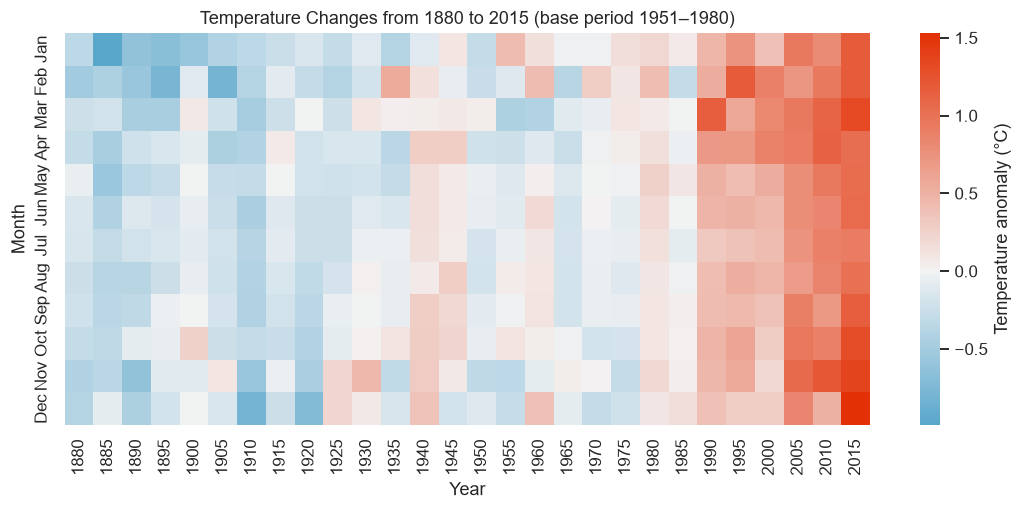

In [3]:
plt.figure(figsize=(10, 4.8), dpi=110)
sns.heatmap(sampled, cmap=heat_colormap, center=0,
            cbar_kws={'label': 'Temperature anomaly (°C)'})
plt.title('Temperature Changes from 1880 to 2015 (base period 1951–1980)')
plt.xlabel('Year')
plt.ylabel('Month')
plt.tight_layout()
plt.savefig('temperature_change.png', dpi=300, bbox_inches='tight')
plt.show()

The sampled later years are generally warmer relative to the 1951–1980 average. Blue represents negative anomalies and red positive anomalies. The supplied historical file ends in 2018; selecting every fifth year from 1880 ends at 2015.